# TAREA : Mejorar el accuracy: clasificación de rostros con SVC

**Enunciado del profesor:** mejorar el accuracy del modelo de la práctica [`05_taller_svm_rostros_profesor.ipynb`](05_taller_svm_rostros_profesor.ipynb), que clasifica rostros del dataset LFW con un `SVC` lineal.

**Punto de partida:** `SVC(kernel='linear', class_weight='balanced')` → **85.27 %** con las 258 fotos de prueba.

**Plan de mejora:**
1. Comparar varios modelos para confirmar cuál es el mejor punto de partida.
2. Escalar los píxeles con `StandardScaler`.
3. Aumentar los datos de entrenamiento con imágenes espejadas.
4. Reducir la dimensionalidad con PCA (de 1850 píxeles a 100 componentes).
5. Buscar los mejores parámetros `C` y `gamma` de un SVM RBF con `GridSearchCV` y validación cruzada.

Se usa la **misma separación** de entrenamiento y prueba que la práctica (`random_state=42`) para que la comparación sea justa.

## 0. Cargar los datos y reproducir el modelo del profesor

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.svm import SVC

In [ ]:
faces = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
x = faces.data
y = faces.target
nombres = faces.target_names
h, w = faces.images.shape[1:]
print('Tamaño de cada foto:', (h, w), '| personas:', len(nombres), '| fotos:', x.shape[0])

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
# Modelo original de la práctica (línea base)
model = SVC(kernel='linear', class_weight='balanced')
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
print(f'Accuracy del modelo del profesor: {accuracy_score(y_test, y_pred)*100:.2f} %')

Accuracy del modelo del profesor: 85.27 %


## 1. Librerías adicionales

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## 2. Comparar varios modelos

Se entrenan cinco modelos con los mismos datos y se comparan sus accuracy en un gráfico de barras.

Regresión Logística : 84.11 %
KNN                 : 58.14 %
Árbol de Decisión   : 45.74 %
SVM lineal          : 85.27 %
SVM RBF             : 79.84 %


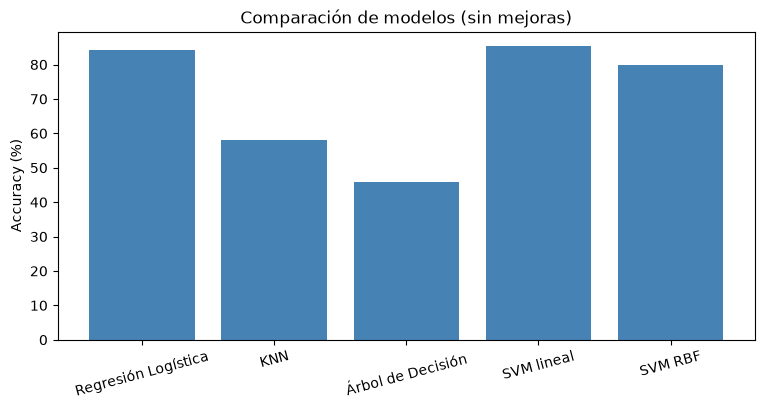

In [ ]:
modelos = {
    'Regresión Logística': LogisticRegression(max_iter=2000),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'SVM lineal': SVC(kernel='linear', class_weight='balanced'),
    'SVM RBF': SVC(kernel='rbf', class_weight='balanced'),
}
resultados = {}
for nombre, modelo in modelos.items():
    modelo.fit(x_train, y_train)
    resultados[nombre] = accuracy_score(y_test, modelo.predict(x_test))
    print(f'{nombre:20s}: {resultados[nombre]*100:.2f} %')

plt.figure(figsize=(9, 4))
plt.bar(resultados.keys(), [v * 100 for v in resultados.values()], color='steelblue')
plt.ylabel('Accuracy (%)')
plt.title('Comparación de modelos (sin mejoras)')
plt.xticks(rotation=15)
plt.show()

## 3. Escalar los píxeles con `StandardScaler`

Cada píxel queda con media 0 y desviación 1. El escalador se ajusta solo con el entrenamiento.

In [ ]:
scaler = StandardScaler()
x_train_esc = scaler.fit_transform(x_train)
x_test_esc = scaler.transform(x_test)

svm_esc = SVC(kernel='linear', class_weight='balanced')
svm_esc.fit(x_train_esc, y_train)
acc_esc = accuracy_score(y_test, svm_esc.predict(x_test_esc))
print(f'SVM lineal con StandardScaler: {acc_esc*100:.2f} %')

SVM lineal con StandardScaler: 85.66 %


## 4. Aumentar los datos con imágenes espejadas

Una cara vista en espejo sigue siendo la misma persona. Se voltea horizontalmente cada foto de **entrenamiento** (nunca las de prueba) y se agrega como un ejemplo nuevo: así el modelo tiene el doble de fotos para aprender.

Fotos de entrenamiento antes: 1030 | después: 2060


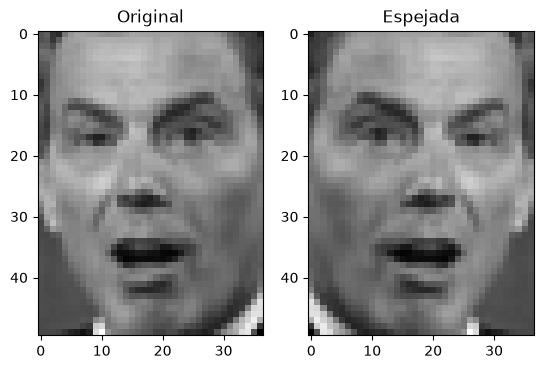

In [ ]:
imgs_train = x_train.reshape(-1, h, w)
espejadas = imgs_train[:, :, ::-1].reshape(len(x_train), -1)   # voltear de izquierda a derecha

x_train_aum = np.vstack([x_train, espejadas])
y_train_aum = np.concatenate([y_train, y_train])
print('Fotos de entrenamiento antes:', len(x_train), '| después:', len(x_train_aum))

plt.subplot(1, 2, 1); plt.imshow(imgs_train[0], cmap='gray'); plt.title('Original')
plt.subplot(1, 2, 2); plt.imshow(espejadas[0].reshape(h, w), cmap='gray'); plt.title('Espejada')
plt.show()

## 5. PCA + SVM RBF optimizado con `GridSearchCV`

- **PCA:** cada foto tiene 1850 píxeles (50 × 37). PCA los resume en **100 componentes** que conservan la mayor parte de la información, quitando ruido y acelerando el entrenamiento. `whiten=True` deja los componentes en la misma escala.
- **SVM RBF:** a diferencia del lineal, puede trazar fronteras curvas entre las personas.
- **GridSearchCV:** prueba todas las combinaciones de `C` (qué tanto castiga los errores) y `gamma` (qué tan "curva" es la frontera) con validación cruzada de 5 partes, y se queda con la mejor.

Todo va dentro de un `pipeline`, así el escalado y el PCA se ajustan solo con los datos de entrenamiento de cada partición.

In [ ]:
pipeline = make_pipeline(
    StandardScaler(),
    PCA(n_components=100, whiten=True, random_state=42),
    SVC(kernel='rbf', class_weight='balanced')
)
parametros = {
    'svc__C': [1, 5, 10, 50, 100],
    'svc__gamma': [0.0005, 0.001, 0.005, 0.01, 'scale'],
}
grid = GridSearchCV(pipeline, parametros, cv=5, n_jobs=-1)
grid.fit(x_train_aum, y_train_aum)

print('Mejores parámetros:', grid.best_params_)
print(f'Accuracy en validación cruzada: {grid.best_score_*100:.2f} %')

Mejores parámetros: {'svc__C': 5, 'svc__gamma': 0.005}
Accuracy en validación cruzada: 87.04 %


## 6. Evaluación final con las fotos de prueba

In [ ]:
y_pred_final = grid.predict(x_test)
acc_final = accuracy_score(y_test, y_pred_final)
aciertos = (y_pred_final == y_test).sum()

print(f'Accuracy final: {acc_final*100:.2f} % ({aciertos} aciertos de {len(y_test)} fotos)')
print(classification_report(y_test, y_pred_final, target_names=nombres))

Accuracy final: 86.82 % (224 aciertos de 258 fotos)
                   precision    recall  f1-score   support

     Ariel Sharon       0.75      0.82      0.78        11
     Colin Powell       0.85      0.94      0.89        47
  Donald Rumsfeld       0.94      0.73      0.82        22
    George W Bush       0.92      0.93      0.93       119
Gerhard Schroeder       0.74      0.89      0.81        19
      Hugo Chavez       0.78      0.54      0.64        13
       Tony Blair       0.83      0.74      0.78        27

         accuracy                           0.87       258
        macro avg       0.83      0.80      0.81       258
     weighted avg       0.87      0.87      0.87       258



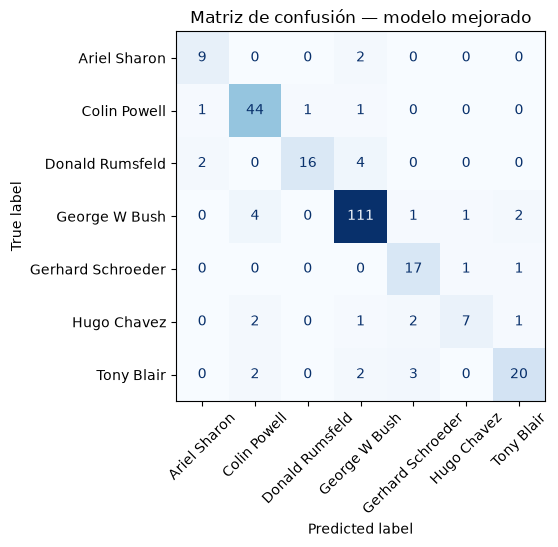

In [ ]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_final), display_labels=nombres).plot(
    xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title('Matriz de confusión — modelo mejorado')
plt.show()

## 7. Comparación: modelo del profesor vs. modelo mejorado

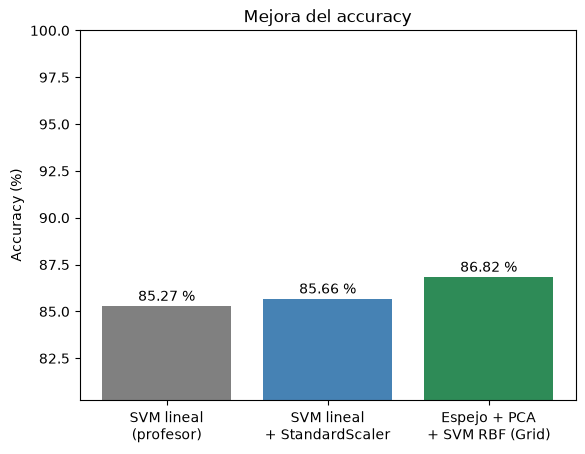

In [ ]:
acc_profesor = accuracy_score(y_test, y_pred)     # y_pred del modelo original del profesor
etiquetas = ['SVM lineal\n(profesor)', 'SVM lineal\n+ StandardScaler', 'Espejo + PCA\n+ SVM RBF (Grid)']
valores = [acc_profesor * 100, acc_esc * 100, acc_final * 100]

plt.bar(etiquetas, valores, color=['gray', 'steelblue', 'seagreen'])
for i, v in enumerate(valores):
    plt.text(i, v + 0.3, f'{v:.2f} %', ha='center')
plt.ylim(min(valores) - 5, 100)
plt.ylabel('Accuracy (%)')
plt.title('Mejora del accuracy')
plt.show()

## 8. Predicciones del modelo mejorado

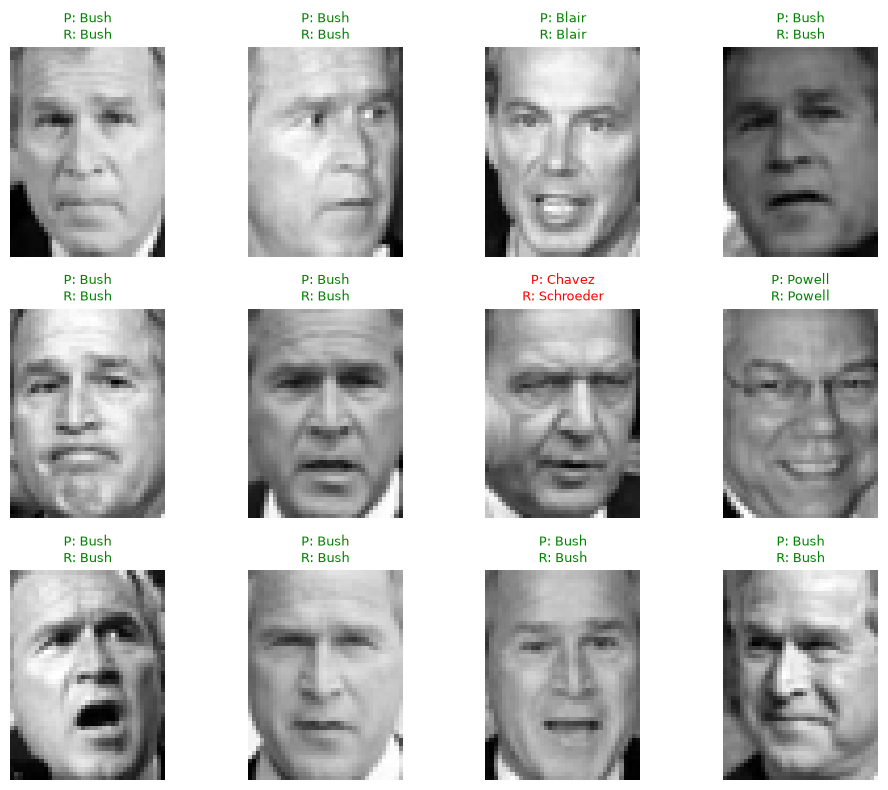

In [ ]:
plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i].reshape(h, w), cmap='gray')
    color = 'green' if y_pred_final[i] == y_test[i] else 'red'
    plt.title('P: ' + nombres[y_pred_final[i]].split()[-1] + '\nR: ' + nombres[y_test[i]].split()[-1], color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 🗒️ Conclusión

Primero se compararon varios modelos y el mejor fue el **SVM lineal (85.27 %)**. Luego se aplicaron cuatro mejoras: escalamiento con `StandardScaler`, aumento de datos con imágenes espejadas, reducción de dimensionalidad con **PCA** (de 1850 píxeles a 100 componentes) y la búsqueda de los mejores `C` y `gamma` de un **SVM RBF** con `GridSearchCV` y validación cruzada. El accuracy final y la cantidad de aciertos se muestran en la sección 6.

**Limitación:** según el `classification_report`, el modelo reconoce mejor a las personas con más fotos (George W Bush, Colin Powell) y tiene más dificultad con las que tienen menos (Hugo Chavez, Donald Rumsfeld). Para mejorar se necesitarían más fotos de esas personas.